# Explicabilidad del modelo de churn

**Proyecto Integrador 1 - The Outliers**

Explicamos el modelo final de `02_modelado.ipynb`, un EBM con las 4 variables finales del escenario principal. Todas las explicaciones salen del propio modelo.

Los datos son sintéticos, la etiqueta parece construida y puede quedar fuga residual (sección 9.2 de `02_modelado.ipynb`).

**Estructura del notebook**

| Sección | Título | Qué se hace |
|---|---|---|
| 1 | Configuración | Librerías, constantes, estilo de las figuras, datos y modelo final |
| 2 | Desempeño del modelo | Comprobación de que el modelo cargado reproduce sus métricas |
| 3 | Explicaciones globales | Importancia de los términos, funciones de forma, interacción y variables relacionadas |
| 4 | Explicaciones individuales | Por qué el modelo clasifica a un cliente como churn o no, con el umbral de 0,5 |
| 5 | Contrafactuales | Qué tendría que cambiar un cliente para cruzar el umbral de 0,5 |
| 6 | Detective de sesgos | La variable del modelo que aún guarda señal y las 3 variables descartadas |
| 7 | Conclusiones | Respuesta al caso y límites de las explicaciones |
| 8 | Uso en el negocio | Cuándo disparar campañas de retención y reconquista, cuál usar y qué meta ponerles |

Las figuras se guardan en `reports/figures/` y las cifras clave en un archivo de resumen.


## 1. Configuración


### 1.1 Librerías y constantes

Usamos el mismo código compartido de `src/churn/` que `02_modelado.ipynb`. 


In [1]:
import json
import sys
from copy import deepcopy
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from churn import data, features
from churn.features import LLAVE, OBJETIVO

SEMILLA = data.SEMILLA
UMBRAL = 0.5 # el que se usa por defecto
DIR_MODELO = data.DIR_MODELADO / "modelo_final"
DIR_FIGURAS = RAIZ / "reports" / "figures"
RUTA_RESUMEN = RAIZ / "reports" / "resumen_xai.json"
RESUMEN = {}   # cifras clave del análisis, se guardan en el Anexo

np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)

### 1.2 Estilo de las figuras

En las figuras de contribuciones con signo, rojo indica que el término empuja hacia churn y azul que empuja hacia no churn.


In [2]:
ROJO, AZUL, GRIS, GRIS_REJILLA, TEXTO = "#e34948", "#2a78d6", "#8a8a85", "#e6e6e3", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.edgecolor": GRIS, "axes.labelcolor": TEXTO, "text.color": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRIS_REJILLA, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.facecolor": "white", "axes.facecolor": "white",
})


def guardar(nombre, fig=None):
    # Guarda la figura actual (o la indicada) en reports/figures/xai_<nombre>.png
    DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = DIR_FIGURAS / f"xai_{nombre}.png"
    (fig or plt.gcf()).savefig(ruta, facecolor="white")
    print(f"Figura guardada: {ruta.relative_to(RAIZ).as_posix()}")

### 1.3 Carga de los datos y del modelo final

Leemos `customer_360` directamente de la tabla de oro del bucket, con Athena, y le aplicamos el mismo pipeline de limpieza y la misma partición de `02_modelado.ipynb`. El modelo final y su configuración se descargan del bucket.


In [3]:
descargados, existentes = data.descargar_modelado()
print(f"archivos descargados de S3: {descargados}. Ya existían: {existentes}")

modelo = joblib.load(DIR_MODELO / "modelo.joblib")
ebm = modelo[-1]   # el pipeline del EBM no transforma las variables (sección 5.1 de 02_modelado.ipynb)
configuracion = json.loads((DIR_MODELO / "configuracion.json").read_text(encoding="utf-8"))
VARIABLES = configuracion["variables"]
VARIABLES_DESCARTADAS = configuracion["variables_retiradas_por_fuga"]

# refrescar=True: lee la tabla de oro del bucket con Athena, sin usar la caché local
c360 = data.normalizar_tipos(data.cargar_customer_360(refrescar=True), features.COLUMNAS_FECHA)
limpio = features.crear_pipeline_limpieza().fit_transform(c360)
limpio = limpio.merge(data.cargar_particion(limpio, OBJETIVO, LLAVE), on=LLAVE, how="inner")

train = limpio[limpio["conjunto"] == "train"].drop(columns="conjunto").sort_values(LLAVE).reset_index(drop=True)
test = limpio[limpio["conjunto"] == "test"].drop(columns="conjunto").sort_values(LLAVE).reset_index(drop=True)
y_train, y_test = train[OBJETIVO].astype(int), test[OBJETIVO].astype(int)
X_train, X_test = train[VARIABLES], test[VARIABLES]

pd.Series({"modelo": configuracion["modelo"],
           "clientes en train": f"{len(train):,}",
           "clientes en test": f"{len(test):,}",
           "variables": ", ".join(VARIABLES),
           "variables descartadas por fuga": ", ".join(VARIABLES_DESCARTADAS),
           "términos del EBM": ", ".join(ebm.term_names_)}).to_frame("valor").style.set_properties(**{"text-align": "left"})

archivos descargados de S3: 0. Ya existían: 25


,valor
modelo,EBM
clientes en train,"350,000"
clientes en test,"150,000"
variables,"summary_total_orders, total_spent, average_order_value, total_returns"
variables descartadas por fuga,"last_purchase_days, return_rate, purchase_frequency"
términos del EBM,"summary_total_orders, total_spent, average_order_value, total_returns, summary_total_orders & total_returns"


Se cargó el EBM con 5 términos: las 4 variables elegidas y la interacción `summary_total_orders & total_returns`.


## 2. Desempeño del modelo

Comprobamos que el modelo cargado reproduce el ROC-AUC y el PR-AUC de la sección 8 de `02_modelado.ipynb`.


In [4]:
probabilidad_test = modelo.predict_proba(X_test)[:, 1]
metricas_modelo = {"roc_auc": float(roc_auc_score(y_test, probabilidad_test)),
                   "pr_auc": float(average_precision_score(y_test, probabilidad_test))}
RESUMEN["desempeno_test"] = metricas_modelo

(pd.DataFrame({"sección 8 de 02_modelado": configuracion["metricas"]["test"], "modelo cargado": metricas_modelo})
 .assign(diferencia=lambda d: d["modelo cargado"] - d["sección 8 de 02_modelado"])
 .rename(index={"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"})
 .style.format("{:.5f}"))

,sección 8 de 02_modelado,modelo cargado,diferencia
ROC-AUC,0.78108,0.78108,0.00000
PR-AUC,0.59633,0.59633,0.00000


## 3. Explicaciones globales: ¿qué mira el modelo en general?


### 3.1 Importancia de los términos


Figura guardada: reports/figures/xai_importancia_terminos.png


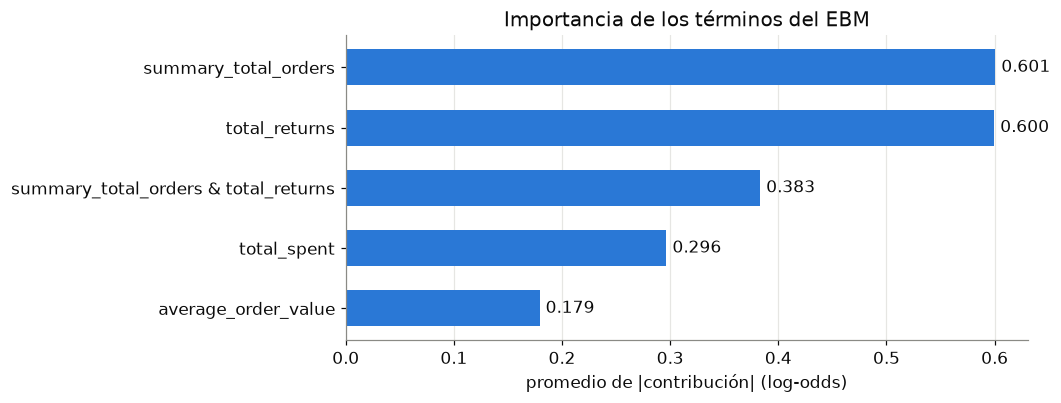

,importancia,% del total
summary_total_orders,0.6006,29.1705
total_returns,0.5995,29.1197
summary_total_orders & total_returns,0.3831,18.6088
total_spent,0.2964,14.3982
average_order_value,0.1792,8.7029


In [5]:
importancia = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()
INTERACCION = next(t for t in ebm.term_names_ if " & " in t)

fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.bar_label(barras, fmt="%.3f", padding=4)
ax.set(title="Importancia de los términos del EBM", xlabel="promedio de |contribución| (log-odds)")
ax.grid(axis="y", visible=False)
guardar("importancia_terminos")
plt.show()

RESUMEN["importancia"] = importancia.sort_values(ascending=False).round(4).to_dict()
(importancia.sort_values(ascending=False).to_frame("importancia")
 .assign(**{"% del total": lambda d: d["importancia"] / d["importancia"].sum() * 100}))

- `summary_total_orders` y `total_returns` son los términos más importantes, con cerca del 29 % del total cada uno.
- Les siguen la interacción, `total_spent` y `average_order_value`.


### 3.2 Funciones de forma: leer el modelo directamente

Graficamos la curva de cada variable con su banda de incertidumbre.


Figura guardada: reports/figures/xai_funciones_forma.png


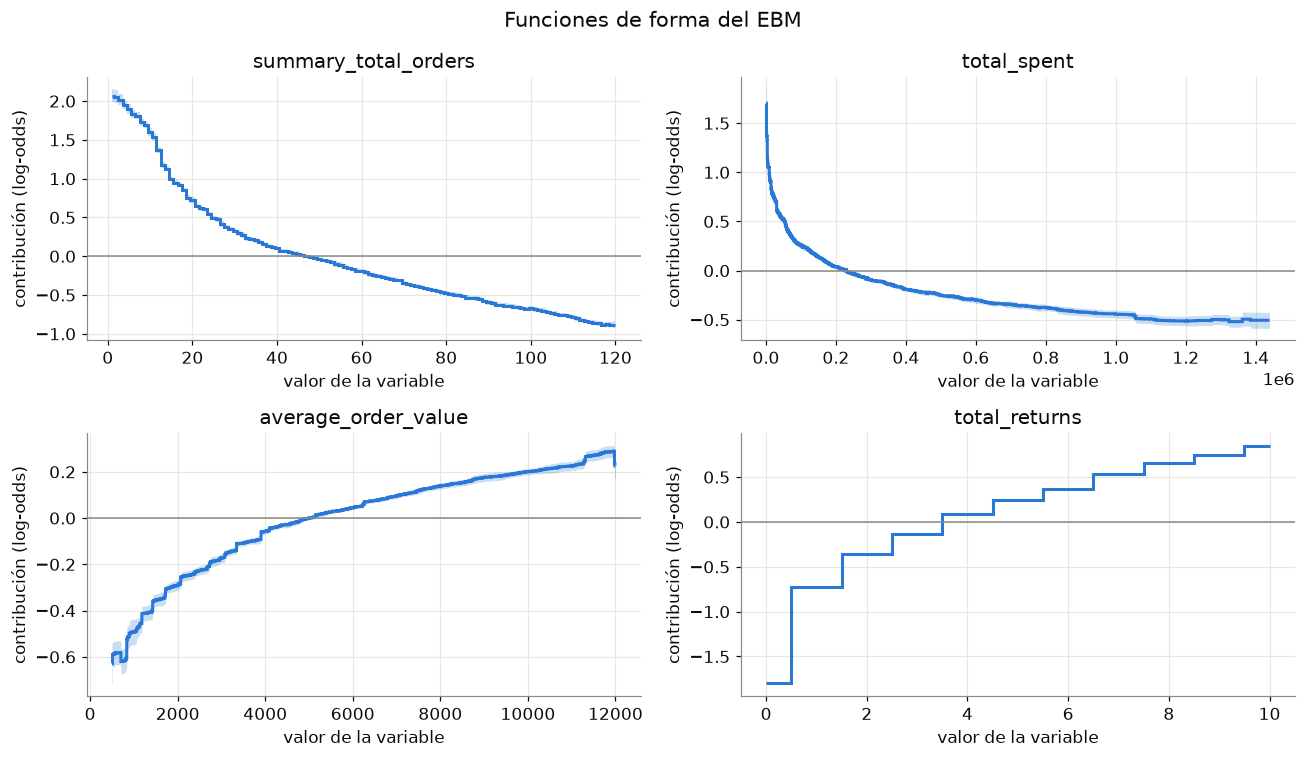

,contribución mínima,desde (mínima),contribución máxima,desde (máxima),rango
variable,,,,,
summary_total_orders,-0.8855,116.5000,2.0687,1.0000,2.9542
total_spent,-0.5200,"1,323,953.6100",1.7024,502.2700,2.2224
average_order_value,-0.6302,500.1200,0.2894,"11,955.0500",0.9196
total_returns,-1.7960,0.0000,0.8457,9.5000,2.6417


In [6]:
explicacion_global = ebm.explain_global()


def forma(termino):
    return explicacion_global.data(ebm.term_names_.index(termino))


fig, axes = plt.subplots(2, 2, figsize=(12, 7))
resumen_formas = []
for ax, variable in zip(axes.ravel(), VARIABLES):
    d = forma(variable)
    bordes = np.asarray(d["names"], dtype=float)
    puntajes, inferior, superior = (np.asarray(d[k], dtype=float) for k in ["scores", "lower_bounds", "upper_bounds"])
    ax.fill_between(bordes, np.r_[inferior, inferior[-1]], np.r_[superior, superior[-1]], step="post",
                    color=AZUL, alpha=0.25, linewidth=0)
    ax.stairs(puntajes, bordes, baseline=None, color=AZUL, linewidth=2)
    ax.axhline(0, color=GRIS, linewidth=1)
    ax.set(title=variable, xlabel="valor de la variable", ylabel="contribución (log-odds)")
    minimo, maximo = int(np.argmin(puntajes)), int(np.argmax(puntajes))
    resumen_formas.append({"variable": variable,
                           "contribución mínima": puntajes[minimo], "desde (mínima)": bordes[minimo],
                           "contribución máxima": puntajes[maximo], "desde (máxima)": bordes[maximo],
                           "rango": puntajes[maximo] - puntajes[minimo]})
fig.suptitle("Funciones de forma del EBM", fontsize=14)
plt.tight_layout()
guardar("funciones_forma")
plt.show()

pd.DataFrame(resumen_formas).set_index("variable")

- `summary_total_orders` baja de +2 con 1 pedido a −0,9 aproximadamente con los valores más altos.
- `total_spent` cae de +1,6 en los valores más bajos a −0,5 desde los 1,2 millones aproximadamente.
- `average_order_value` sube de −0,6 a más de +0,2 y tiene el menor rango.
- `total_returns` sube de −1,8 con 0 devoluciones a +0,8 con 10.
- Las bandas son estrechas y se amplian un poco en los extremos de `total_spent` y `average_order_value`.


### 3.3 La interacción

El modelo final incluye una interacción. La leemos como un mapa de cuánto suma o resta cada combinación de valores, además
de lo que ya aportan las dos curvas por separado.


Figura guardada: reports/figures/xai_interaccion.png


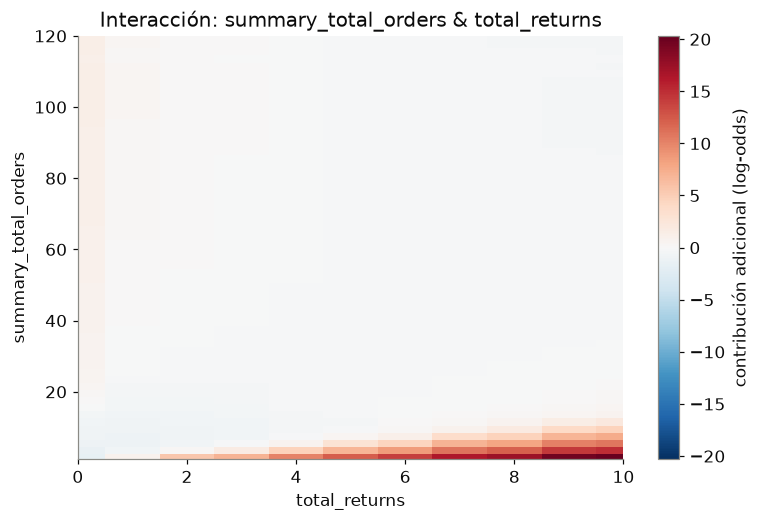

importancia de la interacción: 0.3831 (summary_total_orders: 0.6006, total_returns: 0.5995)


In [7]:
d = forma(INTERACCION)
variable_y, variable_x = INTERACCION.split(" & ")
puntajes = np.asarray(d["scores"], dtype=float)
limite = np.abs(puntajes).max()

fig, ax = plt.subplots(figsize=(8, 5))
malla = ax.pcolormesh(np.asarray(d["right_names"], dtype=float), np.asarray(d["left_names"], dtype=float), puntajes,
                      cmap="RdBu_r", vmin=-limite, vmax=limite)
ax.set(title=f"Interacción: {INTERACCION}", xlabel=variable_x, ylabel=variable_y)
ax.grid(False)
fig.colorbar(malla, ax=ax, label="contribución adicional (log-odds)")
guardar("interaccion")
plt.show()

print(f"importancia de la interacción: {importancia[INTERACCION]:.4f} "
      f"({variable_y}: {importancia[variable_y]:.4f}, {variable_x}: {importancia[variable_x]:.4f})")

La interacción se concentra en los clientes con pocos pedidos y muchas devoluciones, donde suma hasta cerca de +20 log-odds. En el resto del mapa es casi 0.


### 3.4 Variables relacionadas: el efecto del gasto

`total_spent` es el producto de `summary_total_orders` y `average_order_value`. Revisamos cómo se reparte el efecto entre ellas, porque se interpretan en conjunto (sección 5.4 de `02_modelado.ipynb`).


correlación entre total_spent y summary_total_orders × average_order_value: 1.0000


,promedio de |contribución|
summary_total_orders,0.6006
total_spent,0.2964
average_order_value,0.1792
summary_total_orders & total_returns,0.3831
suma de los términos,1.4593
efecto conjunto,0.9139


,total_spent,summary_total_orders,average_order_value
total_spent,1.0000,0.7720,-0.6200
summary_total_orders,0.7720,1.0000,-0.0010
average_order_value,-0.6200,-0.0010,1.0000


Figura guardada: reports/figures/xai_efecto_gasto.png


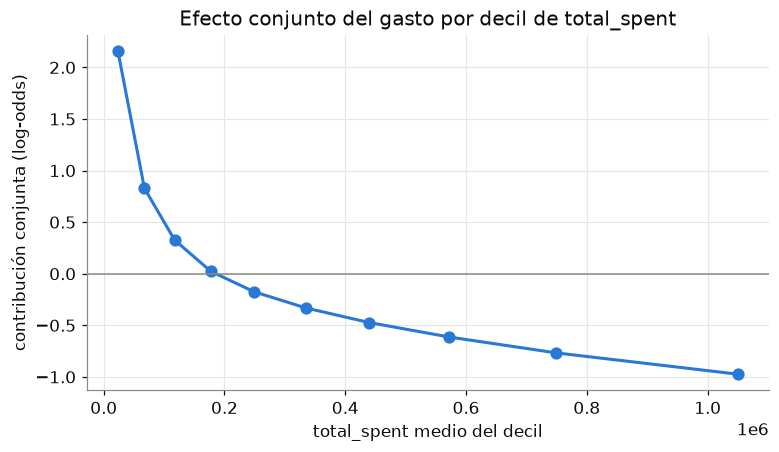

,gasto_medio,efecto_medio
decil,,
1,"23,417.3506",2.1607
2,"67,469.9717",0.8272
3,"117,493.9755",0.3257
4,"177,266.7576",0.0232
5,"248,833.0740",-0.1749
6,"334,765.9633",-0.3322
7,"439,398.1612",-0.4735
8,"572,009.2411",-0.6138
9,"749,677.0378",-0.7681


In [8]:
VARIABLES_GASTO = ["total_spent", "summary_total_orders", "average_order_value"]
producto = X_train["summary_total_orders"] * X_train["average_order_value"]
print(f"correlación entre total_spent y summary_total_orders × average_order_value: {producto.corr(X_train['total_spent']):.4f}")

contribuciones = pd.DataFrame(ebm.eval_terms(X_train), columns=ebm.term_names_)
terminos_gasto = [t for t in ebm.term_names_ if any(v in t.split(" & ") for v in VARIABLES_GASTO)]
efecto_gasto = contribuciones[terminos_gasto].sum(axis=1)

display(pd.Series({**{t: contribuciones[t].abs().mean() for t in terminos_gasto},
                   "suma de los términos": sum(contribuciones[t].abs().mean() for t in terminos_gasto),
                   "efecto conjunto": efecto_gasto.abs().mean()}).to_frame("promedio de |contribución|"))
display(contribuciones[VARIABLES_GASTO].corr().round(3))

por_decil = (pd.DataFrame({"gasto": X_train["total_spent"], "efecto": efecto_gasto})
             .assign(decil=lambda t: pd.qcut(t["gasto"], 10, labels=False) + 1)
             .groupby("decil").agg(gasto_medio=("gasto", "mean"), efecto_medio=("efecto", "mean")))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(por_decil["gasto_medio"], por_decil["efecto_medio"], marker="o", markersize=7, color=AZUL)
ax.axhline(0, color=GRIS, linewidth=1)
ax.set(title="Efecto conjunto del gasto por decil de total_spent", xlabel="total_spent medio del decil",
       ylabel="contribución conjunta (log-odds)")
guardar("efecto_gasto")
plt.show()
por_decil

- `total_spent` coincide con el producto de `summary_total_orders` y `average_order_value` (correlación de 1,0000).
- La suma de las contribuciones por separado es 1,459 y el efecto conjunto 0,914, así que parte de ellas se compensa.
- El efecto conjunto baja de +2,1 en el primer decil de gasto a −1 en el último, y cruza 0 cerca del cuarto decil.


### Conclusiones de las explicaciones globales

- Pedidos y devoluciones son lo que más pesa en el modelo.
- Más pedidos y más gasto restan probabilidad de churn, y más devoluciones la suman.


## 4. Explicaciones individuales: ¿por qué este cliente se clasifica así?

Usamos el umbral de 0,5, el que aplica el EBM por defecto.


### 4.1 Elección de los clientes

Elegimos de `test` un cliente que el modelo clasifica como churn y otro que clasifica como no churn.


In [9]:
clasificacion_test = (probabilidad_test >= UMBRAL).astype(int)
y_real = y_test.to_numpy()
verdaderos_positivos = int(((clasificacion_test == 1) & (y_real == 1)).sum())

display(pd.Series({"clientes clasificados como churn": int(clasificacion_test.sum()),
                   "% de clientes clasificados como churn": clasificacion_test.mean() * 100,
                   "precision": verdaderos_positivos / clasificacion_test.sum(),
                   "recall": verdaderos_positivos / y_real.sum()}).to_frame(f"umbral {UMBRAL}"))


def elegir_cliente(clase):
    # Cliente bien clasificado cuya probabilidad es la más cercana a la mediana de su grupo
    grupo = np.flatnonzero((clasificacion_test == clase) & (y_real == clase))
    return grupo[np.argmin(np.abs(probabilidad_test[grupo] - np.median(probabilidad_test[grupo])))]


CLIENTE_CHURN, CLIENTE_NO_CHURN = elegir_cliente(1), elegir_cliente(0)
posiciones = [CLIENTE_CHURN, CLIENTE_NO_CHURN]
(X_test.iloc[posiciones]
 .assign(**{LLAVE: test[LLAVE].iloc[posiciones].to_numpy(), "probabilidad": probabilidad_test[posiciones],
            "churn real": y_real[posiciones]})
 .set_axis(["clasificado como churn", "clasificado como no churn"]).T)

,umbral 0.5
clientes clasificados como churn,"13,025.0000"
% de clientes clasificados como churn,8.6833
precision,0.7631
recall,0.3201


,clasificado como churn,clasificado como no churn
summary_total_orders,2.0000,69.0000
total_spent,"18,243.9600","362,801.3100"
average_order_value,"9,121.9800","5,257.9900"
total_returns,1.0000,4.0000
customer_id,"1,340,006.0000","1,113,773.0000"
probabilidad,0.8292,0.1134
churn real,1.0000,0.0000


- Con el umbral de 0,5, el modelo clasifica como churn a 13.025 clientes (el 8,68% del total de test), con precision de 0,763 y recall de 0,320.
- El cliente clasificado como churn tiene 2 pedidos, 1 devolución y probabilidad de 0,829. El clasificado como no churn tiene 69
  pedidos, 4 devoluciones y probabilidad de 0,113. Los dos están bien clasificados.


### 4.2 Explicación del Cliente clasificado como churn

intercepto -1.5558 + contribuciones 3.1361 = log-odds 1.5803
probabilidad por la suma 0.829246 | probabilidad del modelo 0.829246 | clasificación con umbral 0.5: churn
Figura guardada: reports/figures/xai_cliente_churn.png


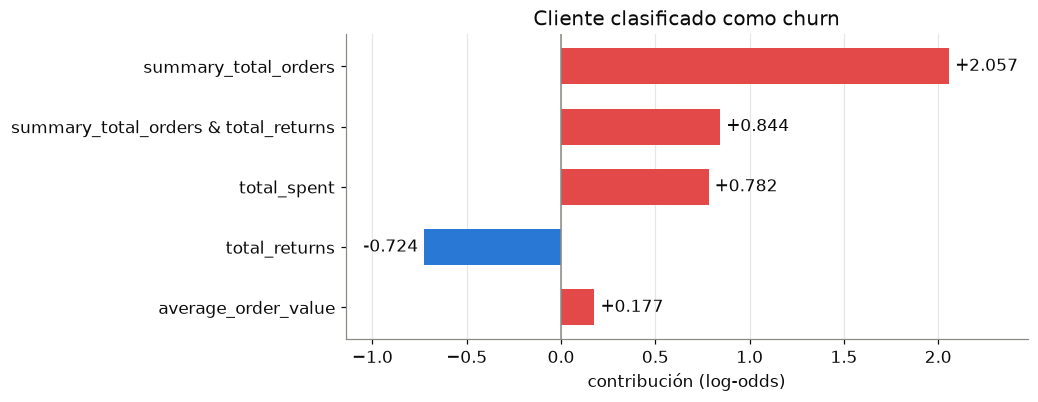

,contribución (log-odds)
summary_total_orders,2.0575
summary_total_orders & total_returns,0.8438
total_spent,0.7823
total_returns,-0.7245
average_order_value,0.1771


In [10]:
def explicar_cliente(posicion, titulo, nombre_figura):
    # Contribución de cada término al log-odds del cliente, y comprobación de la aditividad exacta
    cliente = X_test.iloc[[posicion]]
    contribucion = pd.Series(ebm.eval_terms(cliente)[0], index=ebm.term_names_)
    intercepto = float(np.ravel(ebm.intercept_)[0])
    log_odds = intercepto + contribucion.sum()
    probabilidad_suma = 1 / (1 + np.exp(-log_odds))
    probabilidad_modelo = modelo.predict_proba(cliente)[0, 1]
    print(f"intercepto {intercepto:.4f} + contribuciones {contribucion.sum():.4f} = log-odds {log_odds:.4f}")
    print(f"probabilidad por la suma {probabilidad_suma:.6f} | probabilidad del modelo {probabilidad_modelo:.6f} | "
          f"clasificación con umbral {UMBRAL}: {'churn' if probabilidad_modelo >= UMBRAL else 'no churn'}")

    ordenada = contribucion.reindex(contribucion.abs().sort_values().index)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    barras = ax.barh(ordenada.index, ordenada.values, height=0.6, color=[ROJO if v > 0 else AZUL for v in ordenada.values])
    ax.bar_label(barras, fmt="%+.3f", padding=4)
    ax.axvline(0, color=GRIS, linewidth=1)
    ax.margins(x=0.15)
    ax.set(title=titulo, xlabel="contribución (log-odds)")
    ax.grid(axis="y", visible=False)
    guardar(nombre_figura)
    plt.show()
    return contribucion.sort_values(key=np.abs, ascending=False).to_frame("contribución (log-odds)")


explicar_cliente(CLIENTE_CHURN, "Cliente clasificado como churn", "cliente_churn")

- El intercepto (−1,5558) más las contribuciones (3,1361) da un log-odds de 1,5803, y la probabilidad coincide con la del modelo (0,8292).
- Empujan hacia churn `summary_total_orders`, la interacción, `total_spent` y `average_order_value`. Solo `total_returns` resta (−0,72).


### 4.3 Explicación del Cliente clasificado como no churn


intercepto -1.5558 + contribuciones -0.5005 = log-odds -2.0564
probabilidad por la suma 0.113410 | probabilidad del modelo 0.113410 | clasificación con umbral 0.5: no churn
Figura guardada: reports/figures/xai_cliente_no_churn.png


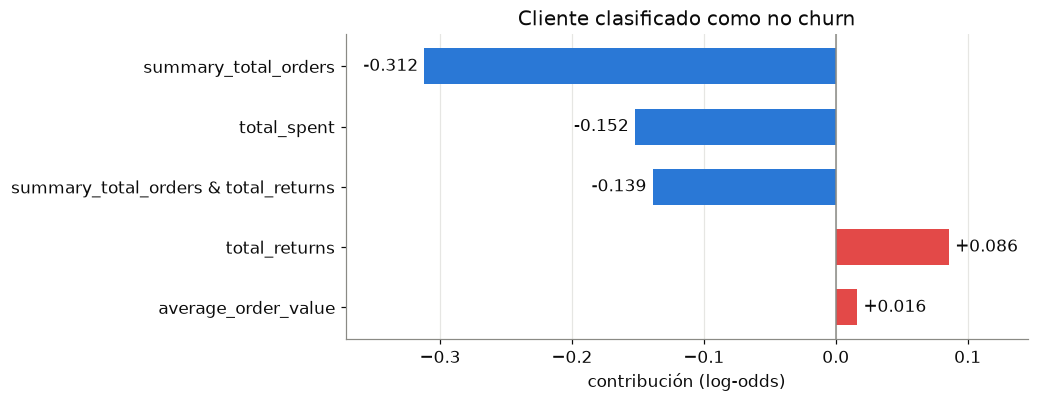

,contribución (log-odds)
summary_total_orders,-0.3119
total_spent,-0.1522
summary_total_orders & total_returns,-0.1388
total_returns,0.0859
average_order_value,0.0164


In [11]:
explicar_cliente(CLIENTE_NO_CHURN, "Cliente clasificado como no churn", "cliente_no_churn")

- El intercepto (−1,5558) más las contribuciones (−0,5005) da un log-odds de −2,0564, y la probabilidad coincide con la del modelo (0,1134).
- Empujan hacia no churn `summary_total_orders`, `total_spent` y la interacción. `total_returns` suma +0,09 y `average_order_value` +0,02.


### Conclusiones de las explicaciones individuales

- En los dos clientes, la suma de los términos reproduce exactamente la probabilidad del modelo.
- `summary_total_orders` es el término de mayor peso en ambos.
- **Cliente clasificado como churn:** ha hecho solo 2 pedidos y ha gastado 18.243,96 en total, lo que lo ubica entre el 10 % de los clientes que menos gastan. Además, tiene 1 devolución en esos 2 pedidos. Para el modelo, alguien que ha comprado tan poco tiene mucho riesgo de irse. Tener una sola devolución le ayuda un poco y su valor promedio de 9.121,98 por pedido casi no influye, pero no alcanza a compensar. Por eso le asigna un 83% de probabilidad de abandono.
- **Cliente clasificado como no churn:** ha hecho 69 pedidos y ha gastado 362.801,31, más que al menos la mitad de los clientes. Para el modelo, esa actividad indica un cliente que tiende a quedarse. Sus 4 devoluciones suben un poco el riesgo, pero son pocas frente a sus pedidos, y su valor promedio de 5.257,99 por pedido casi no influye. Por eso le asigna solo un 11 % de probabilidad de abandono.

## 5. Contrafactuales

¿Qué tendría que cambiar para que el cliente no quede marcado como churn?

### 5.1 Variables que se pueden mover

Definimos qué cambios son coherentes, porque `total_spent` debe seguir siendo el producto de `summary_total_orders` y
`average_order_value`.


In [12]:
VARIABLES_MOVIBLES = ["summary_total_orders", "average_order_value", "total_returns"]
rangos = X_train[VARIABLES].agg(["min", "max"])
REJILLAS = {"summary_total_orders": np.arange(rangos.loc["min", "summary_total_orders"], rangos.loc["max", "summary_total_orders"] + 1),
            "average_order_value": np.linspace(rangos.loc["min", "average_order_value"], rangos.loc["max", "average_order_value"], 120),
            "total_returns": np.arange(rangos.loc["min", "total_returns"], rangos.loc["max", "total_returns"] + 1)}
cliente_caso = X_test.iloc[[CLIENTE_CHURN]].reset_index(drop=True)
probabilidad_caso = modelo.predict_proba(cliente_caso)[0, 1]


def variantes(cliente, **valores):
    # Una fila por combinación de `valores`, con total_spent coherente y sin más devoluciones que pedidos
    rejilla = pd.MultiIndex.from_product(list(valores.values()), names=list(valores)).to_frame(index=False)
    filas = cliente.loc[cliente.index.repeat(len(rejilla))].reset_index(drop=True)
    for variable in valores:
        filas[variable] = rejilla[variable].astype(float)
    filas["total_spent"] = (cliente["total_spent"].iloc[0]
                            * filas["summary_total_orders"] / cliente["summary_total_orders"].iloc[0]
                            * filas["average_order_value"] / cliente["average_order_value"].iloc[0])
    validas = filas["total_returns"] <= filas["summary_total_orders"]
    return rejilla[validas].reset_index(drop=True), filas.loc[validas, VARIABLES].reset_index(drop=True)


(rangos.T.assign(cliente=cliente_caso.iloc[0])
 .assign(tratamiento=lambda d: ["se recalcula" if v == "total_spent" else "se mueve" for v in d.index])
 [["cliente", "min", "max", "tratamiento"]])

,cliente,min,max,tratamiento
summary_total_orders,2.0000,1.0000,120.0000,se mueve
total_spent,"18,243.9600",502.2700,"1,439,544.0000",se recalcula
average_order_value,"9,121.9800",500.1200,"11,999.9900",se mueve
total_returns,1.0000,0.0000,10.0000,se mueve


El cliente tiene 2 pedidos, 1 devolución, un valor promedio de 9.121,98 y un gasto total de 18.243,96. Se mueven 3 variables dentro de
su rango observado y `total_spent` se recalcula.


### 5.2 Moviendo una variable

Para el cliente de la sección 4.2 cambiamos una variable a la vez, dejando fijas las demás, y buscamos el valor con el que
su probabilidad baja de 0,5.


Figura guardada: reports/figures/xai_barrido_una_variable.png


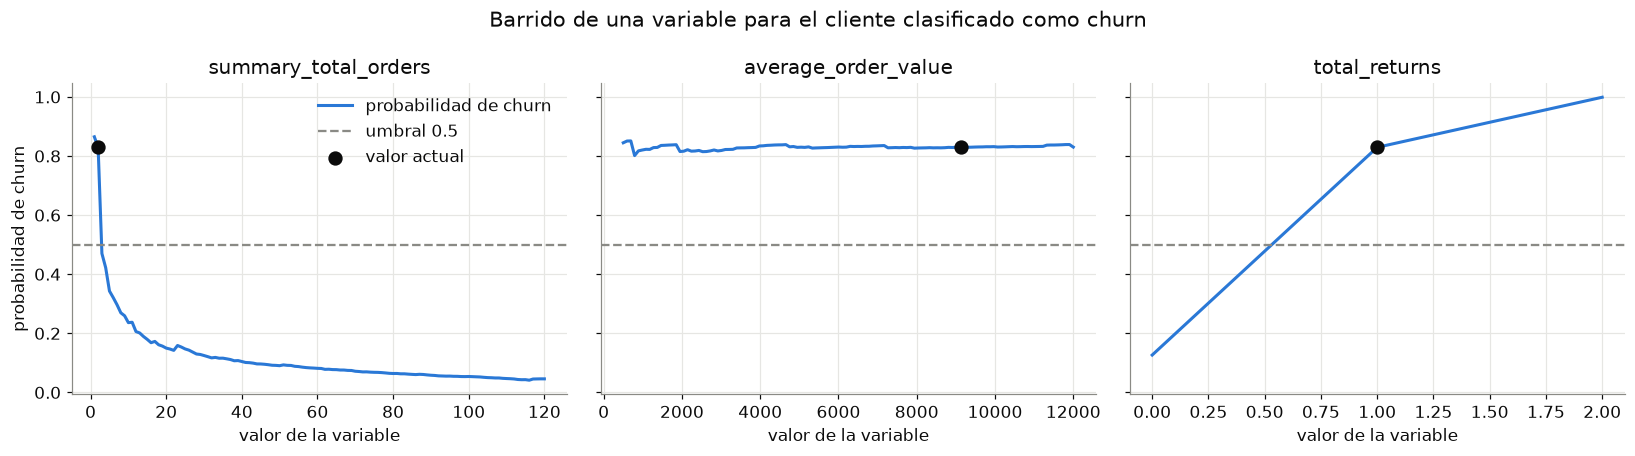

,valor actual,valor más cercano bajo el umbral,cambio necesario,probabilidad mínima,rango de probabilidad
variable,,,,,
summary_total_orders,2.0000,3.0000,1.0000,0.0412,0.8237
average_order_value,"9,121.9800",NaN,NaN,0.8013,0.0497
total_returns,1.0000,0.0000,-1.0000,0.1263,0.8724


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
resumen_barridos = []
for ax, variable in zip(axes, VARIABLES_MOVIBLES):
    rejilla, filas = variantes(cliente_caso, **{variable: REJILLAS[variable]})
    probabilidad = modelo.predict_proba(filas)[:, 1]
    actual = cliente_caso[variable].iloc[0]
    debajo = rejilla.loc[probabilidad < UMBRAL, variable]
    mas_cercano = debajo.iloc[(debajo - actual).abs().argmin()] if len(debajo) else np.nan
    ax.plot(rejilla[variable], probabilidad, color=AZUL, label="probabilidad de churn")
    ax.axhline(UMBRAL, color=GRIS, linewidth=1.5, linestyle="--", label=f"umbral {UMBRAL}")
    ax.scatter([actual], [probabilidad_caso], s=70, color=TEXTO, zorder=5, label="valor actual")
    ax.set(title=variable, xlabel="valor de la variable")
    resumen_barridos.append({"variable": variable, "valor actual": actual, "valor más cercano bajo el umbral": mas_cercano,
                             "cambio necesario": mas_cercano - actual, "probabilidad mínima": probabilidad.min(),
                             "rango de probabilidad": np.ptp(probabilidad)})
axes[0].set_ylabel("probabilidad de churn")
axes[0].legend(frameon=False)
fig.suptitle("Barrido de una variable para el cliente clasificado como churn", fontsize=14)
plt.tight_layout()
guardar("barrido_una_variable")
plt.show()

resumen_barridos = pd.DataFrame(resumen_barridos).set_index("variable")
resumen_barridos

- Un pedido más (de 2 a 3) o una devolución menos (de 1 a 0) dejan al cliente por debajo de 0,5.
- `average_order_value` no lo logra con ningún valor: la probabilidad mínima es 0,801.
- Con 2 pedidos, `total_returns` solo puede ser 0, 1 o 2, y con 2 la probabilidad se acerca a 1.


### 5.3 Moviendo dos variables a la vez

Movemos a la vez las dos variables con mayor efecto para ver qué combinaciones dejan al cliente por debajo de 0,5.


Figura guardada: reports/figures/xai_barrido_dos_variables.png


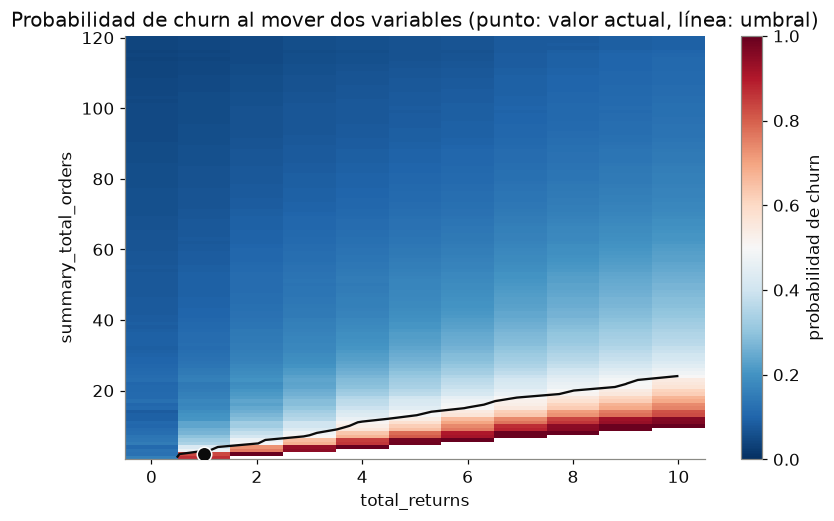

Combinación más cercana bajo el umbral: total_returns = 1.00 (actual 1.00), summary_total_orders = 3.00 (actual 2.00), probabilidad 0.470


In [14]:
variable_x, variable_y = resumen_barridos["rango de probabilidad"].sort_values(ascending=False).index[:2]
rejilla, filas = variantes(cliente_caso, **{variable_x: REJILLAS[variable_x], variable_y: REJILLAS[variable_y]})
rejilla["probabilidad"] = modelo.predict_proba(filas)[:, 1]
matriz = rejilla.pivot(index=variable_y, columns=variable_x, values="probabilidad")

fig, ax = plt.subplots(figsize=(8.5, 5))
malla = ax.pcolormesh(matriz.columns, matriz.index, matriz.values, shading="nearest", cmap="RdBu_r", vmin=0, vmax=1)
if rejilla["probabilidad"].min() < UMBRAL < rejilla["probabilidad"].max():
    ax.contour(matriz.columns, matriz.index, matriz.values, levels=[UMBRAL], colors=TEXTO, linewidths=1.5)
ax.scatter([cliente_caso[variable_x].iloc[0]], [cliente_caso[variable_y].iloc[0]], s=90, color=TEXTO, edgecolor="white", zorder=5)
ax.set(title="Probabilidad de churn al mover dos variables (punto: valor actual, línea: umbral)", xlabel=variable_x, ylabel=variable_y)
ax.grid(False)
fig.colorbar(malla, ax=ax, label="probabilidad de churn")
guardar("barrido_dos_variables")
plt.show()

# Combinación bajo el umbral más cercana al cliente, con cada variable medida como fracción de su rango
distancia = sum((rejilla[v] - cliente_caso[v].iloc[0]).abs() / np.ptp(REJILLAS[v]) for v in [variable_x, variable_y])
debajo = rejilla["probabilidad"] < UMBRAL
if debajo.any():
    mejor = rejilla.loc[distancia[debajo].idxmin()]
    print(f"Combinación más cercana bajo el umbral: {variable_x} = {mejor[variable_x]:,.2f} "
          f"(actual {cliente_caso[variable_x].iloc[0]:,.2f}), {variable_y} = {mejor[variable_y]:,.2f} "
          f"(actual {cliente_caso[variable_y].iloc[0]:,.2f}), probabilidad {mejor['probabilidad']:.3f}")
else:
    print("Ninguna combinación de estas dos variables lleva al cliente por debajo del umbral")

- La combinación más cercana bajo el umbral es pasar de 2 a 3 pedidos con 1 devolución, con probabilidad de 0,470.
- A más devoluciones se necesitan más pedidos para quedar bajo el umbral: con 10 devoluciones, cerca de 24 pedidos.


### Conclusiones de los contrafactuales

Para este cliente, un solo cambio en pedidos o en devoluciones modifica la clasificación, y `average_order_value` no la modifica.


## 6. Detective de sesgos

Auditamos las variables con la propia importancia del EBM: la del modelo final que aún guarda señal de la etiqueta y las 3 que se descartaron por fuga.


### 6.1 ¿Qué variable del modelo aún guarda señal?

Revisamos la importancia de las 4 variables que dejamos y cuál conserva relación con las variables que parecen formar la etiqueta (sección 5.6 de `02_modelado.ipynb`).


In [15]:
def auc_univariado(serie, y):
    auc = roc_auc_score(y, serie)
    return max(auc, 1 - auc)


senal = pd.DataFrame({"AUC univariado": {v: auc_univariado(X_train[v], y_train) for v in VARIABLES},
                      "importancia en el EBM": importancia[VARIABLES]})
for descartada in VARIABLES_DESCARTADAS:
    senal[f"correlación con {descartada}"] = [X_train[v].corr(train[descartada]) for v in VARIABLES]

VARIABLE_CON_SENAL = senal["AUC univariado"].idxmax()
RESUMEN["variable_con_senal"] = VARIABLE_CON_SENAL
print(f"Variable del modelo con más señal por sí sola: {VARIABLE_CON_SENAL}")
print("correlación de total_returns / summary_total_orders con return_rate: "
      f"{(train['total_returns'] / train['summary_total_orders']).corr(train['return_rate']):.4f}")
senal.sort_values("AUC univariado", ascending=False)

Variable del modelo con más señal por sí sola: summary_total_orders
correlación de total_returns / summary_total_orders con return_rate: 1.0000


,AUC univariado,importancia en el EBM,correlación con last_purchase_days,correlación con return_rate,correlación con purchase_frequency
summary_total_orders,0.7447,0.6006,0.0004,-0.5818,0.3011
total_spent,0.6962,0.2964,-0.0014,-0.3964,0.2042
total_returns,0.5895,0.5995,-0.0005,0.3122,0.0310
average_order_value,0.5012,0.1792,-0.0006,-0.0002,-0.0011


- `summary_total_orders` tiene el mayor AUC univariado y la mayor importancia.
- Su correlación es de −0,582 con `return_rate`, 0,301 con `purchase_frequency` y casi 0 con `last_purchase_days`.
- `total_returns` dividido entre `summary_total_orders` coincide con `return_rate` (correlación de 1,0000).


### 6.2 Experimento A: las 3 variables descartadas

Reentrenamos el EBM agregando `last_purchase_days`, `return_rate` y `purchase_frequency`, una a una y las 3 juntas, y vemos como se comportan las métricas y qué importancia toma cada una.


Figura guardada: reports/figures/xai_detective_descartadas.png


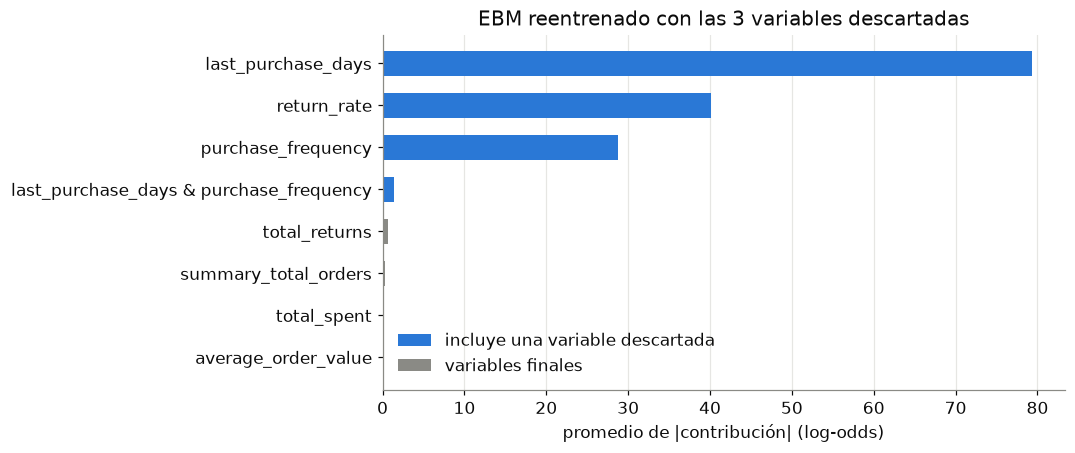

,ROC-AUC,PR-AUC,% de la importancia de lo agregado
4 variables finales,0.77882,0.59512,-
+ last_purchase_days,0.98716,0.94238,35.7
+ return_rate,0.77890,0.59708,54.1
+ purchase_frequency,0.80944,0.61078,38.9
+ las 3 descartadas,0.99999,0.99995,99.2


In [16]:
# Se entrena y evalúa en el primer fold de train (el mismo de 02_modelado.ipynb), sin volver a usar test
entrenamiento, validacion = next(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(train, y_train))


def medir(ajustado, columnas):
    probabilidad = ajustado.predict_proba(train.iloc[validacion][columnas])[:, 1]
    return {"ROC-AUC": roc_auc_score(y_train.iloc[validacion], probabilidad),
            "PR-AUC": average_precision_score(y_train.iloc[validacion], probabilidad)}


def evaluar_ebm(columnas):
    ajustado = ExplainableBoostingClassifier(n_jobs=-1, random_state=SEMILLA, **configuracion["hiperparametros"])
    ajustado.fit(train.iloc[entrenamiento][columnas], y_train.iloc[entrenamiento])
    return ajustado, medir(ajustado, columnas)


ebm_base, metricas_base = evaluar_ebm(VARIABLES)
experimentos = {"4 variables finales": metricas_base}
for nombre, agregadas in {**{f"+ {v}": [v] for v in VARIABLES_DESCARTADAS}, "+ las 3 descartadas": VARIABLES_DESCARTADAS}.items():
    ajustado, metricas = evaluar_ebm(VARIABLES + agregadas)
    importancias = pd.Series(ajustado.term_importances(), index=ajustado.term_names_)
    terminos_agregados = [t for t in importancias.index if any(v in t.split(" & ") for v in agregadas)]
    experimentos[nombre] = {**metricas, "% de la importancia de lo agregado": importancias[terminos_agregados].sum() / importancias.sum() * 100}
    if len(agregadas) == 3:
        importancia_contaminado = importancias.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
es_agregada = [any(v in t.split(" & ") for v in VARIABLES_DESCARTADAS) for t in importancia_contaminado.index]
ax.barh(importancia_contaminado.index, importancia_contaminado.values, height=0.6, color=[AZUL if e else GRIS for e in es_agregada])
ax.barh([0], [0], color=AZUL, label="incluye una variable descartada")
ax.barh([0], [0], color=GRIS, label="variables finales")
ax.set(title="EBM reentrenado con las 3 variables descartadas", xlabel="promedio de |contribución| (log-odds)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False)
guardar("detective_descartadas")
plt.show()

RESUMEN["experimento_descartadas"] = {k: {m: round(float(x), 5) for m, x in v.items()} for k, v in experimentos.items()}
pd.DataFrame(experimentos).T.style.format({"ROC-AUC": "{:.5f}", "PR-AUC": "{:.5f}", "% de la importancia de lo agregado": "{:.1f}"}, na_rep="-")

- Agregar `last_purchase_days` sube el ROC-AUC de 0,779 a 0,987 y agregar `purchase_frequency` a 0,809. Con `return_rate` casi no cambia, pasa a 0,779.
- Con las 3 juntas llega a 1, y los términos que las incluyen suman el 99,2 % de la importancia.
- En ese modelo con las 3 variables descartadas `last_purchase_days` es el término más importante, seguido de `return_rate` y `purchase_frequency`.

### 6.3 Experimento B: quitar la variable que aún guarda señal

Con un EBM se puede borrar un término sin reentrenar. Comparamos el modelo editado con uno reentrenado sin esa variable.


In [17]:
ebm_editado = deepcopy(ebm_base)
ebm_editado.remove_terms([t for t in ebm_editado.term_names_ if VARIABLE_CON_SENAL in t.split(" & ")])

sin_variable = [v for v in VARIABLES if v != VARIABLE_CON_SENAL]
sin_variable_ni_gasto = [v for v in sin_variable if v != "total_spent"]   # total_spent permite reconstruir los pedidos

auditoria = {"4 variables finales": metricas_base,
             f"EBM editado (sin términos de {VARIABLE_CON_SENAL})": medir(ebm_editado, VARIABLES),
             f"reentrenado sin {VARIABLE_CON_SENAL}": evaluar_ebm(sin_variable)[1],
             f"reentrenado sin {VARIABLE_CON_SENAL} ni total_spent": evaluar_ebm(sin_variable_ni_gasto)[1]}

RESUMEN["experimento_variable_con_senal"] = {k: {m: round(float(x), 5) for m, x in v.items()} for k, v in auditoria.items()}
pd.DataFrame(auditoria).T.assign(**{"diferencia de ROC-AUC": lambda d: d["ROC-AUC"] - d["ROC-AUC"].iloc[0]}).style.format("{:.5f}")

,ROC-AUC,PR-AUC,diferencia de ROC-AUC
4 variables finales,0.77882,0.59512,0.00000
EBM editado (sin términos de summary_total_orders),0.71596,0.45887,-0.06286
reentrenado sin summary_total_orders,0.77595,0.58820,-0.00287
reentrenado sin summary_total_orders ni total_spent,0.58659,0.25102,-0.19223


- Borrar los términos de `summary_total_orders` sin reentrenar baja el ROC-AUC de 0,779 a 0,716.
- Reentrenar sin ella casi no cambia el resultado.
- Reentrenar sin ella ni `total_spent` lo baja a 0,587.


### 6.4 Conclusiones del detective de sesgos

- Las 3 variables descartadas concentran casi toda la importancia cuando se agregan al modelo. Esto respalda que sean una fuga de información y que la etiqueta se haya construido con ellas.
- El ROC-AUC solo cae de forma marcada al quitar juntas `summary_total_orders` y `total_spent`.


## 7. Conclusiones

**Respuesta al caso**

- El modelo identifica el riesgo de abandono a partir del historial de compras. Con el umbral de 0,5, marca como churn al 8,7 % de los clientes con una precision de 0,763.
- Lo que más pesa son los pedidos y las devoluciones (sección 3.1). Los clientes con pocos pedidos, poco gasto y muchas devoluciones son los de mayor riesgo, y los que tienen muchos pedidos y gastan más tienden a quedarse (secciones 3.2 y 3.4).
- El riesgo más alto aparece cuando se juntan pocos pedidos y muchas devoluciones.
- El valor promedio por pedido es lo que menos influye: tiene la menor importancia (8,7 %) y no cambia la clasificación del cliente analizado.

**Límites de estas explicaciones**

- Describen cómo decide el modelo, no por qué abandonan los clientes (decisión 37 del EDA). Los contrafactuales tampoco garantizan que conseguir un pedido más retenga a un cliente.
- Las 3 variables descartadas llevan el ROC-AUC a 1 y concentran el 99,2 % de la importancia (sección 6.2), lo que respalda haberlas retirado por fuga. Pedidos y devoluciones permiten reconstruir `return_rate` (sección 6.1), así que parte de la señal del modelo puede seguir viniendo de la forma en que se construyó la etiqueta. Aún así las conservamos porque son variables de interés para el negocio.
- La información de los pedidos está repetida, porque `total_spent` es el producto de los pedidos y del valor promedio. Por eso quitar los pedidos casi no cambia el resultado (0,776) y solo al quitar también el gasto cae a 0,587 (sección 6.3). Estas variables se interpretan en conjunto (sección 3.4).

## 8. Uso en el negocio: campañas de retención y reconquista

**¿Cuándo disparar una campaña?**

- Cada mes se calcula la probabilidad de churn de todos los clientes activos con el modelo elegido.
- Se dispara la campaña para los clientes con probabilidad mayor o igual a 0,5 o según como se defina con el negocio
- Si existen limitaciones para contactarlos a todos, se empieza por los de mayor probabilidad: el 10 % de mayor riesgo concentra cerca del 35% del churn según lo que nos indicó la curva de ganancia acumulada.

**Estrategias del negocio al cliente**

La explicación de cada cliente muestra qué variable le suma más riesgo, según este se puede definir la campaña:

| Motivo principal | Qué significa | Campaña sugerida |
|---|---|---|
| `summary_total_orders` o `total_spent` | Pocos pedidos y/o poco gasto | Reactivación: un incentivo para la siguiente compra, como un descuento, envío gratis o un recordatorio de recompra |
| `total_returns` o la interacción | Muchas devoluciones frente a sus pedidos | Atención posventa: contacto de servicio, revisión del motivo de las devoluciones y opción de cambio en lugar de devolución |

Para `average_order_value` no hacemos una campaña porque casi nunca es el motivo principal.

**Proponer metas por cliente**

- El contrafactual de cada cliente indica el cambio más pequeño que lo deja por debajo de 0,5 (sección 5). Para el cliente analizado basta 1 pedido más o 1 devolución menos, así que la meta de su campaña sería lograr su tercer pedido o evitar su siguiente devolución.
- La meta cambia según el cliente: con más devoluciones hacen falta más pedidos para salir del riesgo. Los clientes que necesitan cambios muy grandes son más costosos de recuperar y pueden quedar en un segundo plano.

**Reconquista de clientes que ya se fueron**

Para los clientes que ya abandonaron, la misma explicación indica su motivo principal y permite personalizar la oferta de regreso: un incentivo de compra si tenían pocos pedidos, o la solución de sus devoluciones si ese fue el motivo.


## Anexo: cifras clave del análisis


In [18]:
RUTA_RESUMEN.write_text(json.dumps(RESUMEN, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(RESUMEN, ensure_ascii=False, indent=2))

{
  "desempeno_test": {
    "roc_auc": 0.7810836772242771,
    "pr_auc": 0.5963344019512526
  },
  "importancia": {
    "summary_total_orders": 0.6006,
    "total_returns": 0.5995,
    "summary_total_orders & total_returns": 0.3831,
    "total_spent": 0.2964,
    "average_order_value": 0.1792
  },
  "variable_con_senal": "summary_total_orders",
  "experimento_descartadas": {
    "4 variables finales": {
      "ROC-AUC": 0.77882,
      "PR-AUC": 0.59512
    },
    "+ last_purchase_days": {
      "ROC-AUC": 0.98716,
      "PR-AUC": 0.94238,
      "% de la importancia de lo agregado": 35.7189
    },
    "+ return_rate": {
      "ROC-AUC": 0.7789,
      "PR-AUC": 0.59708,
      "% de la importancia de lo agregado": 54.13695
    },
    "+ purchase_frequency": {
      "ROC-AUC": 0.80944,
      "PR-AUC": 0.61078,
      "% de la importancia de lo agregado": 38.8898
    },
    "+ las 3 descartadas": {
      "ROC-AUC": 0.99999,
      "PR-AUC": 0.99995,
      "% de la importancia de lo agregado":

El resumen reúne las cifras de las secciones 2, 3 y 6.
